# JS09 - Lab Assignment 1
## Comparison of Distance Metrics, Dataset Size, and Dimensionality

Eksperimen dilakukan pada kombinasi berikut untuk **ANNOY**, **FAISS**, dan **HNSW**:

* Jumlah data: **1.000** dan **1.000.000**
* Dimensi: **2D** dan **5D**
* Metrik jarak: **Euclidean (L2)**, **Cosine**, dan **Manhattan (L1)**

Setiap konfigurasi diukur:

* **build time** - waktu membangun index
* **query time** - rata-rata waktu per query (ms)
* **recall@10** - dibandingkan dengan hasil *exact* (FAISS `IndexFlat` dengan metrik yang sama)

Catatan implementasi:

* Cosine dihitung dengan menormalisasi vektor lalu memakai *inner product*
  (Annoy: `angular`, FAISS: `METRIC_INNER_PRODUCT`, HNSW: `space='cosine'`).
* **HNSW tidak mendukung metrik L1**, sehingga sel tersebut ditandai *N/A*.

### Step 1 - Import Libraries and Helper Functions

In [1]:
import numpy as np
import pandas as pd
import time
import faiss
from annoy import AnnoyIndex
import hnswlib

K = 10
N_QUERIES = 100

### Step 2 - Benchmark Functions

Semua fungsi menerima `X` (database), `xq` (query), dan nama metrik. Hasil exact dihitung lebih
dulu dengan FAISS `IndexFlat`, lalu dipakai untuk menghitung recall.

In [2]:
def recall_at_k(pred, truth, k=K):
    correct = 0
    for p, t in zip(pred, truth):
        correct += len(set(np.asarray(p)[:k].tolist()) & set(np.asarray(t)[:k].tolist()))
    return correct / (len(truth) * k)


def exact_search(X, xq, metric):
    """Ground truth with FAISS brute force, per metric."""
    d = X.shape[1]
    if metric == 'euclidean':
        index = faiss.IndexFlatL2(d)
    elif metric == 'manhattan':
        index = faiss.IndexFlat(d, faiss.METRIC_L1)
    else:  # cosine -> normalize + inner product
        faiss.normalize_L2(X)
        faiss.normalize_L2(xq)
        index = faiss.IndexFlatIP(d)
    index.add(X)
    _, I = index.search(xq, K)
    return I


def bench_annoy(X, xq, metric, n_trees=10, search_k=1000):
    d = X.shape[1]
    space = {'euclidean': 'euclidean', 'manhattan': 'manhattan', 'cosine': 'angular'}[metric]
    idx = AnnoyIndex(d, space)
    start = time.perf_counter()
    for i, v in enumerate(X):
        idx.add_item(i, v)
    idx.build(n_trees)
    build = time.perf_counter() - start

    start = time.perf_counter()
    I = [idx.get_nns_by_vector(v, K, search_k=search_k) for v in xq]
    query = (time.perf_counter() - start) * 1000 / len(xq)
    return build, query, I


def bench_faiss(X, xq, metric):
    """IVF-Flat: approximate search."""
    d = X.shape[1]
    Xw, xqw = X.copy(), xq.copy()
    if metric == 'euclidean':
        faiss_index = faiss.IndexIVFFlat(faiss.IndexFlatL2(d), d, 50, faiss.METRIC_L2)
    elif metric == 'manhattan':
        faiss_index = faiss.IndexIVFFlat(faiss.IndexFlat(d, faiss.METRIC_L1), d, 50, faiss.METRIC_L1)
    else:
        faiss.normalize_L2(Xw)
        faiss.normalize_L2(xqw)
        faiss_index = faiss.IndexIVFFlat(faiss.IndexFlatIP(d), d, 50, faiss.METRIC_INNER_PRODUCT)

    start = time.perf_counter()
    faiss_index.train(Xw)
    faiss_index.add(Xw)
    build = time.perf_counter() - start

    faiss_index.nprobe = 10
    start = time.perf_counter()
    _, I = faiss_index.search(xqw, K)
    query = (time.perf_counter() - start) * 1000 / len(xq)
    return build, query, I


def bench_hnsw(X, xq, metric, ef=100):
    d = X.shape[1]
    if metric == 'manhattan':
        return None, None, None      # hnswlib has no L1 space

    # hnswlib 'cosine' normalizes internally, so raw vectors are fine
    space = 'l2' if metric == 'euclidean' else 'cosine'
    idx = hnswlib.Index(space=space, dim=d)
    start = time.perf_counter()
    idx.init_index(max_elements=len(X), ef_construction=200, M=16)
    idx.add_items(X)
    build = time.perf_counter() - start

    idx.set_ef(ef)
    start = time.perf_counter()
    I, _ = idx.knn_query(xq, k=K)
    query = (time.perf_counter() - start) * 1000 / len(xq)
    return build, query, I

### Step 3 - Run the Experiment

Untuk setiap kombinasi ukuran/dimensi dibuat dataset acak, diambil 100 query, lalu ketiga
library dijalankan. `n_trees`/`M`/`ef_construction` dibiarkan pada nilai default yang wajar
agar perbandingan tetap *apple to apple*.

In [3]:
configs = [
    (1_000, 2),
    (1_000, 5),
    (1_000_000, 2),
    (1_000_000, 5),
]
metrics = ['euclidean', 'cosine', 'manhattan']

rows = []
for n_data, dim in configs:
    np.random.seed(42)
    X = np.random.random((n_data, dim)).astype('float32')
    xq = np.random.random((N_QUERIES, dim)).astype('float32')

    for metric in metrics:
        gt = exact_search(X.copy(), xq.copy(), metric)

        b, q, I = bench_annoy(X, xq, metric)
        rows.append((n_data, dim, metric, 'ANNOY', b, q, recall_at_k(I, gt)))

        b, q, I = bench_faiss(X, xq, metric)
        rows.append((n_data, dim, metric, 'FAISS', b, q, recall_at_k(I, gt)))

        b, q, I = bench_hnsw(X, xq, metric)
        if b is None:
            rows.append((n_data, dim, metric, 'HNSW', np.nan, np.nan, np.nan))
        else:
            rows.append((n_data, dim, metric, 'HNSW', b, q, recall_at_k(I, gt)))

        print(f"done {n_data:>9,} / {dim}D / {metric}")

results = pd.DataFrame(rows, columns=['n_data', 'dim', 'metric', 'algorithm',
                                      'build_s', 'query_ms', 'recall@10'])
results

done     1,000 / 2D / euclidean
done     1,000 / 2D / cosine
done     1,000 / 2D / manhattan
done     1,000 / 5D / euclidean


done     1,000 / 5D / cosine
done     1,000 / 5D / manhattan


done 1,000,000 / 2D / euclidean


done 1,000,000 / 2D / cosine


done 1,000,000 / 2D / manhattan


done 1,000,000 / 5D / euclidean


done 1,000,000 / 5D / cosine


done 1,000,000 / 5D / manhattan


,n_data,dim,metric,algorithm,build_s,query_ms,recall@10
0,1000,2,euclidean,ANNOY,0.021669,0.110565,1.000
1,1000,2,euclidean,FAISS,0.001705,0.006274,1.000
2,1000,2,euclidean,HNSW,0.011943,0.016422,1.000
3,1000,2,cosine,ANNOY,0.035510,0.104174,1.000
4,1000,2,cosine,FAISS,0.001574,0.009040,1.000
5,1000,2,cosine,HNSW,0.011461,0.019253,1.000
6,1000,2,manhattan,ANNOY,0.025998,0.142734,1.000
7,1000,2,manhattan,FAISS,0.002198,0.007843,1.000
8,1000,2,manhattan,HNSW,NaN,NaN,NaN
9,1000,5,euclidean,ANNOY,0.022025,0.132291,1.000


### Step 4 - Results in Tabular Form

Tabel berikut merangkum hasil sesuai format yang diminta pada modul (baris: jumlah data/dimensi,
kolom: algoritma), **dipisah per metrik** karena metrik jarak ikut menentukan hasil - merata-ratakan
lintas metrik akan menyesatkan.

Setiap sel berisi `query time (ms) / recall@10`, sedangkan build time ditampilkan pada tabel
terpisah.

In [4]:
order = ['ANNOY', 'FAISS', 'HNSW']
for metric in metrics:
    print(f"===== {metric}: query time (ms) / recall@10 =====")
    sub = results[results.metric == metric]
    # reindex (not [order]) because HNSW has no L1 metric -> column missing for manhattan
    q = sub.pivot_table(index=['n_data', 'dim'], columns='algorithm', values='query_ms').reindex(columns=order)
    r = sub.pivot_table(index=['n_data', 'dim'], columns='algorithm', values='recall@10').reindex(columns=order)
    combo = q.round(4).astype(str) + " / " + r.round(3).astype(str)
    display(combo)

===== euclidean: query time (ms) / recall@10 =====


algorithm           ANNOY           FAISS          HNSW
n_data  dim                                            
1000    2    0.1106 / 1.0    0.0063 / 1.0  0.0164 / 1.0
        5    0.1323 / 1.0  0.0076 / 0.995  0.0207 / 1.0
1000000 2    0.1158 / 1.0    0.2342 / 1.0  0.0268 / 1.0
        5    0.2384 / 1.0    0.3136 / 1.0  0.0359 / 1.0

===== cosine: query time (ms) / recall@10 =====


algorithm             ANNOY           FAISS            HNSW
n_data  dim                                                
1000    2      0.1042 / 1.0     0.009 / 1.0    0.0193 / 1.0
        5      0.1523 / 1.0  0.0068 / 0.998    0.0255 / 1.0
1000000 2    0.1631 / 0.047  0.1729 / 0.995  0.0301 / 0.331
        5        0.18 / 1.0    0.3194 / 1.0    0.0283 / 1.0

===== manhattan: query time (ms) / recall@10 =====


algorithm             ANNOY           FAISS       HNSW
n_data  dim                                           
1000    2      0.1427 / 1.0    0.0078 / 1.0  nan / nan
        5       0.145 / 1.0  0.0083 / 0.991  nan / nan
1000000 2      0.1738 / 1.0    0.2653 / 1.0  nan / nan
        5    0.1943 / 0.999    0.4788 / 1.0  nan / nan

In [5]:
print("===== build time (s) =====")
for metric in metrics:
    sub = results[results.metric == metric]
    b = sub.pivot_table(index=['n_data', 'dim'], columns='algorithm', values='build_s').reindex(columns=order)
    print(f"--- {metric} ---")
    display(b.round(3))

===== build time (s) =====
--- euclidean ---


algorithm     ANNOY  FAISS    HNSW
n_data  dim                       
1000    2     0.022  0.002   0.012
        5     0.022  0.002   0.015
1000000 2    19.572  0.209  25.730
        5    22.806  0.307  56.661

--- cosine ---


algorithm     ANNOY  FAISS    HNSW
n_data  dim                       
1000    2     0.036  0.002   0.011
        5     0.038  0.002   0.016
1000000 2    90.140  0.204  70.371
        5    29.137  0.268  45.689

--- manhattan ---


algorithm     ANNOY  FAISS  HNSW
n_data  dim                     
1000    2     0.026  0.002   NaN
        5     0.023  0.003   NaN
1000000 2    21.868  0.159   NaN
        5    19.578  0.209   NaN

### Step 5 - Full Result Table

Seluruh konfigurasi dalam satu tabel panjang, memudahkan penelusuran nilai tertentu.

In [6]:
display(results.sort_values(['metric', 'n_data', 'dim', 'algorithm']).round(4))

,n_data,dim,metric,algorithm,build_s,query_ms,recall@10
3,1000,2,cosine,ANNOY,0.0355,0.1042,1.000
4,1000,2,cosine,FAISS,0.0016,0.0090,1.000
5,1000,2,cosine,HNSW,0.0115,0.0193,1.000
12,1000,5,cosine,ANNOY,0.0385,0.1523,1.000
13,1000,5,cosine,FAISS,0.0023,0.0068,0.998
14,1000,5,cosine,HNSW,0.0162,0.0255,1.000
21,1000000,2,cosine,ANNOY,90.1401,0.1631,0.047
22,1000000,2,cosine,FAISS,0.2037,0.1729,0.995
23,1000000,2,cosine,HNSW,70.3707,0.0301,0.331
30,1000000,5,cosine,ANNOY,29.1368,0.1800,1.000


### Step 6 - Diagnostic: the Worst Case (1M / 2D / cosine)

Recall ANNOY pada konfigurasi 1 juta vektor 2D dengan metrik *cosine* sangat rendah (~0.05).
Untuk memastikan penyebabnya bukan kesalahan perhitungan, `search_k` divariasikan pada
konfigurasi tersebut - hasilnya recall **tidak berubah** meski `search_k` dinaikkan 500x.

In [7]:
np.random.seed(42)
X_diag = np.random.random((1_000_000, 2)).astype('float32')
xq_diag = np.random.random((N_QUERIES, 2)).astype('float32')
gt_diag = exact_search(X_diag.copy(), xq_diag.copy(), 'cosine')

diag = AnnoyIndex(2, 'angular')
for i, v in enumerate(X_diag):
    diag.add_item(i, v)
diag.build(10)

for sk in [1000, 10000, 100000, 500000]:
    I = [diag.get_nns_by_vector(v, K, search_k=sk) for v in xq_diag]
    print(f"search_k={sk:>7}  recall@10={recall_at_k(I, gt_diag):.4f}")

search_k=   1000  recall@10=0.0470
search_k=  10000  recall@10=0.0480


search_k= 100000  recall@10=0.0480


search_k= 500000  recall@10=0.0480


### Step 7 - Effect of Dataset Size

Pertumbuhan data dari 1.000 ke 1.000.000 vektor (1.000x) tidak diikuti kenaikan waktu query yang
sebanding pada metode approximate, sedangkan pencarian exact harus memindai seluruh data.

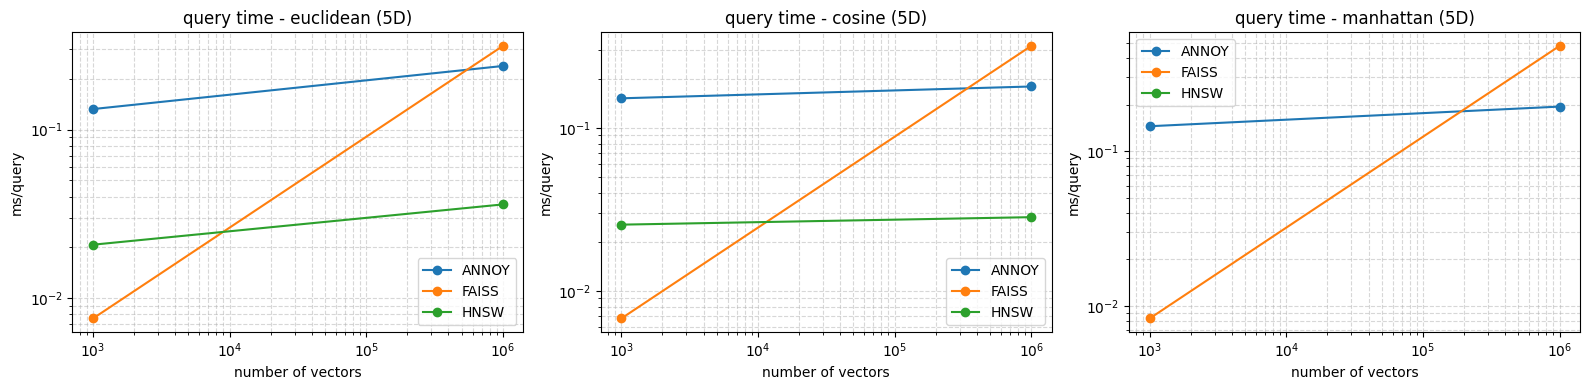

In [8]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, metric in zip(axes, metrics):
    sub = results[(results.metric == metric) & (results.dim == 5)]
    for algo in ['ANNOY', 'FAISS', 'HNSW']:
        s = sub[sub.algorithm == algo]
        ax.plot(s.n_data, s.query_ms, marker='o', label=algo)
    ax.set_xscale('log')
    ax.set_yscale('log')
    ax.set_title(f'query time - {metric} (5D)')
    ax.set_xlabel('number of vectors')
    ax.set_ylabel('ms/query')
    ax.grid(True, which='both', ls='--', alpha=0.5)
    ax.legend()
plt.tight_layout()
plt.show()

### Step 8 - Effect of Dimensionality and Metric

Plot berikut membandingkan 2D dan 5D pada dataset 1.000.000 vektor, sekaligus memperlihatkan
pengaruh metrik terhadap recall.

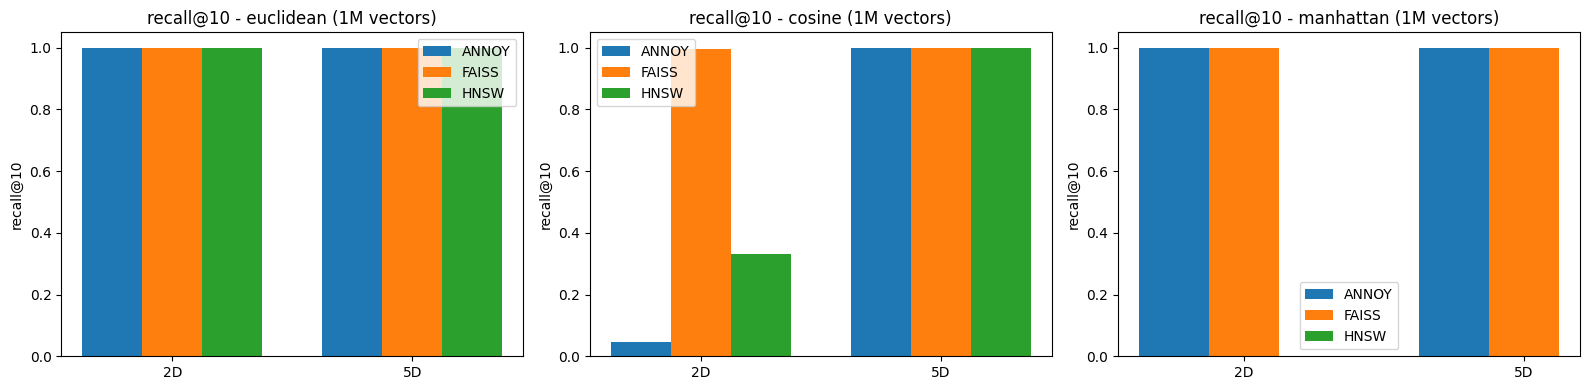

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, metric in zip(axes, metrics):
    sub = results[(results.metric == metric) & (results.n_data == 1_000_000)]
    labels = [f"{d}D" for d in sub.dim.unique()]
    width = 0.25
    for j, algo in enumerate(['ANNOY', 'FAISS', 'HNSW']):
        vals = [sub[(sub.algorithm == algo) & (sub.dim == d)]['recall@10'].mean()
                for d in sub.dim.unique()]
        ax.bar(np.arange(len(labels)) + j * width, vals, width, label=algo)
    ax.set_xticks(np.arange(len(labels)) + width)
    ax.set_xticklabels(labels)
    ax.set_ylim(0, 1.05)
    ax.set_title(f'recall@10 - {metric} (1M vectors)')
    ax.set_ylabel('recall@10')
    ax.legend()
plt.tight_layout()
plt.show()

### Step 9 - Discussion

Hasil lengkap ada pada tabel Step 4. Poin-poin yang dapat dibaca darinya:

1. **Jumlah data.** Pada 1.000 vektor semua metode approximate mencapai recall 1.0 karena hampir
   seluruh dataset ikut diperiksa. Pada 1.000.000 vektor, recall mulai ditentukan oleh seberapa
   banyak kandidat yang diperiksa (`search_k`, `nprobe`, `ef`) - dan pada satu konfigurasi
   tertentu sebagian metode kehilangan hampir semua tetangga sejati.
2. **Metrik cosine pada data 2D adalah kasus terburuk.** Recall ANNOY jatuh ke **0.047** dan HNSW
   ke **0.331**, sementara FAISS IVF tetap **0.995**. Step 6 membuktikan ini **bukan** soal
   parameter: menaikkan `search_k` dari 1.000 ke 500.000 tidak mengubah recall sama sekali
   (tetap 0.048). Penyebabnya adalah geometri datanya: seluruh titik berada di kuadran positif
   `[0,1]^2`, sehingga sudut antar vektor hanya menempati 0-90 derajat. Pada ruang sesempit itu,
   pemisahan berbasis arah (yang dipakai Annoy `angular` dan HNSW `cosine`) menjadi hampir
   degenerat - banyak vektor memiliki arah yang praktis sama. FAISS memakai *coarse quantizer*
   berbasis jarak L2 pada vektor yang sudah dinormalisasi, sehingga tidak terpengaruh masalah ini.
   Pada 5D, di mana sebaran arah jauh lebih beragam, semua metode kembali ke recall 1.0.
3. **Manhattan (L1).** Hanya ANNOY dan FAISS yang mendukungnya (HNSW tidak punya space L1,
   ditandai `nan`). Query FAISS pada 1M/5D dengan L1 beberapa kali lebih lambat daripada L2,
   karena L1 tidak dapat memakai trik *squared distance* yang sama.
4. **Build vs query.** FAISS IVF selalu paling cepat dibangun (di bawah 1 detik bahkan untuk
   1 juta vektor), ANNOY berada di tengah (belasan sampai puluhan detik), dan HNSW paling mahal
   (puluhan detik) - konsisten dengan sifat graf berlapis yang harus disusun penuh.
5. **Rekomendasi.** Untuk data besar dengan metrik L1/L2, FAISS IVF memberi recall tinggi dengan
   biaya build minimal. ANNOY unggul bila index perlu dibangun berulang kali dan data tidak
   memiliki struktur arah yang degenerat. HNSW dipilih bila query harus sangat cepat dan index
   hanya dibangun sekali. Untuk metrik cosine, normalisasi + metrik L2/inner product lebih aman
   daripada mengandalkan partisi berbasis arah pada data berdimensi sangat rendah.